In [73]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/varpit94/bitcoin-data-updated-till-26jun2021/BTC-USD.csv


# *1 -  Load Data and Explore data*

In [74]:
df = pd.read_csv("/kaggle/input/datasets/varpit94/bitcoin-data-updated-till-26jun2021/BTC-USD.csv")
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,2014-09-17,465.864014,468.174011,452.421997,457.334015,457.334015,21056800
1,2014-09-18,456.859985,456.859985,413.104004,424.440002,424.440002,34483200
2,2014-09-19,424.102997,427.834991,384.532013,394.795990,394.795990,37919700
3,2014-09-20,394.673004,423.295990,389.882996,408.903992,408.903992,36863600
4,2014-09-21,408.084991,412.425995,393.181000,398.821014,398.821014,26580100


In [75]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2747 non-null   object 
 1   Open       2747 non-null   float64
 2   High       2747 non-null   float64
 3   Low        2747 non-null   float64
 4   Close      2747 non-null   float64
 5   Adj Close  2747 non-null   float64
 6   Volume     2747 non-null   int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 150.4+ KB


In [76]:
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year

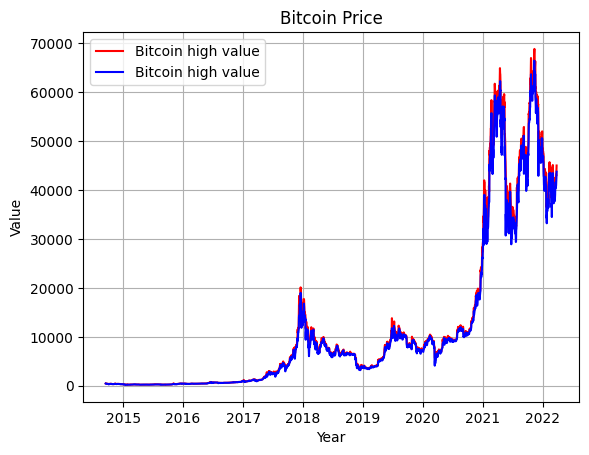

In [77]:
import matplotlib.pyplot as plt
plt.plot(df["Date"],df["High"],c = "red",label = "Bitcoin high value")
plt.plot(df["Date"],df["Low"],c = "blue",label = "Bitcoin high value")
plt.legend()
plt.xlabel("Year")
plt.ylabel("Value")
plt.title("Bitcoin Price")
plt.grid()
plt.show()

In [78]:
# Mean Price according to years
bitcoin_mean = df.groupby("Year")["Close"].mean().reset_index()
bitcoin_mean

,Year,Close
0,2014,363.693085
1,2015,272.453381
2,2016,568.492407
3,2017,4006.033629
4,2018,7572.298947
5,2019,7395.246282
6,2020,11116.378092
7,2021,47436.932021
8,2022,40933.435361


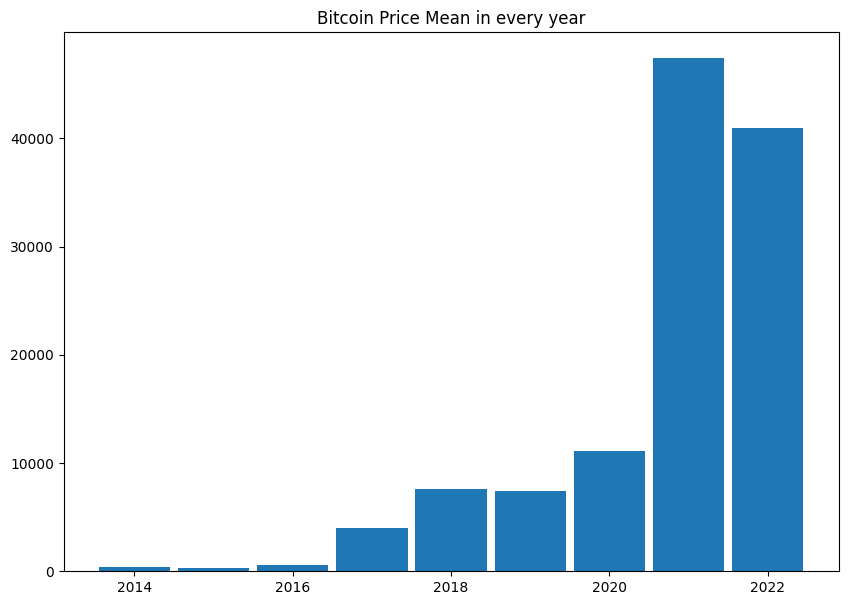

In [79]:
plt.figure(figsize = (10,7))
plt.bar(data = bitcoin_mean,height = "Close",x = "Year",width = 0.9)
plt.title("Bitcoin Price Mean in every year")
plt.show()

<Axes: >

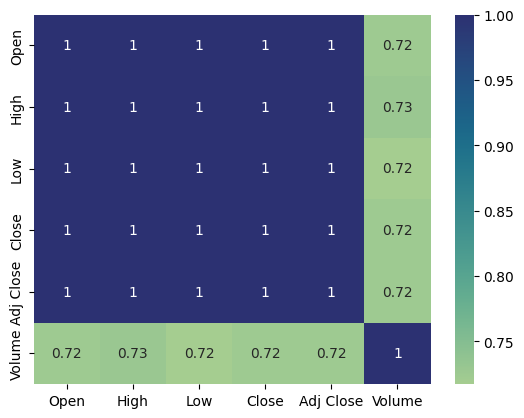

In [80]:
# With volume and Price
numeric = df.select_dtypes(include = ["int","float"]).columns.to_list()
numeric.remove("Year")
corr = df[numeric].corr()

import seaborn as sns
plt.figure()
sns.heatmap(corr,annot = True,cmap="crest")

In [81]:
df.describe()

,Date,Open,High,Low,Close,Adj Close,Volume,Year
count,2747,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000,2.747000e+03,2747.000000
mean,2018-06-21 00:00:00,11668.600272,11981.034949,11325.596907,11682.892098,11682.892098,1.484704e+10,2017.967965
min,2014-09-17 00:00:00,176.897003,211.731003,171.509995,178.102997,178.102997,5.914570e+06,2014.000000
25%,2016-08-03 12:00:00,609.122009,611.894501,606.309479,609.234009,609.234009,8.161285e+07,2016.000000
50%,2018-06-21 00:00:00,6371.850098,6500.870117,6285.629883,6376.709961,6376.709961,5.227550e+09,2018.000000
75%,2020-05-07 12:00:00,10728.271485,10992.468751,10412.890137,10755.395019,10755.395019,2.500517e+10,2020.000000
max,2022-03-25 00:00:00,67549.734375,68789.625000,66382.062500,67566.828125,67566.828125,3.509679e+11,2022.000000
std,NaN,16323.683853,16759.568657,15825.584507,16330.191582,16330.191582,1.994819e+10,2.197892


In [82]:
df.set_index("Date",inplace = True)
df.head()

,Open,High,Low,Close,Adj Close,Volume,Year
Date,,,,,,,
2014-09-17,465.864014,468.174011,452.421997,457.334015,457.334015,21056800,2014
2014-09-18,456.859985,456.859985,413.104004,424.440002,424.440002,34483200,2014
2014-09-19,424.102997,427.834991,384.532013,394.795990,394.795990,37919700,2014
2014-09-20,394.673004,423.295990,389.882996,408.903992,408.903992,36863600,2014
2014-09-21,408.084991,412.425995,393.181000,398.821014,398.821014,26580100,2014


<Axes: xlabel='Date'>

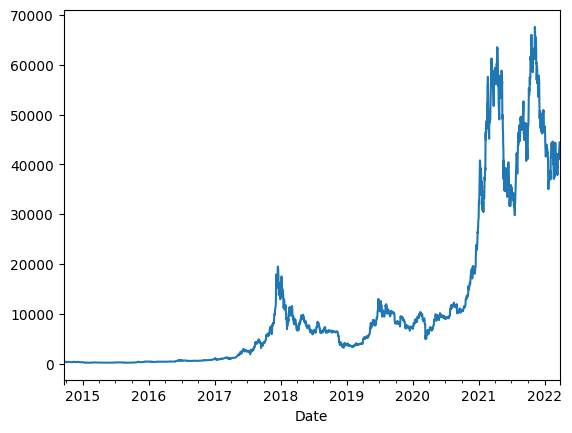

In [83]:
df["Adj Close"].plot()

In [84]:
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from sklearn.metrics import mean_squared_error

variables = ["Open","High","Low","Volume","Adj Close"]
df[variables].head()

,Open,High,Low,Volume,Adj Close
Date,,,,,
2014-09-17,465.864014,468.174011,452.421997,21056800,457.334015
2014-09-18,456.859985,456.859985,413.104004,34483200,424.440002
2014-09-19,424.102997,427.834991,384.532013,37919700,394.795990
2014-09-20,394.673004,423.295990,389.882996,36863600,408.903992
2014-09-21,408.084991,412.425995,393.181000,26580100,398.821014


In [85]:
data = df[variables].copy()
var = data.drop(columns = ["Adj Close"],axis = 1)
value = data["Adj Close"].values.reshape(-1,1)

scaler_x = MinMaxScaler()
scaler_y = MinMaxScaler()
var_scaled = scaler_x.fit_transform(var)
value_scaled = scaler_y.fit_transform(value)

def create_sliding_window(var,target,window_size):
    X = []
    y = []
    for i in range(len(var) - window_size):
        X.append(var[i:i + window_size])
        y.append(target[i + window_size])
    return np.array(X),np.array(y)

In [86]:
window_size = 7 # 1 week
X,y = create_sliding_window(var_scaled,value_scaled,window_size)
X.shape,y.shape

((2740, 7, 4), (2740, 1))

In [87]:
split = int(len(X) * 0.7)
X_train = X[:split]
X_test = X[split:]
y_train = y[:split]
y_test = y[split:]

In [89]:
# model
model = tf.keras.Sequential([
    tf.keras.layers.LSTM(64,activation = "tanh"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1)
])

model.compile(loss = "mse",optimizer = "adam",metrics = ["mae"])

early_stop = tf.keras.callbacks.EarlyStopping(monitor = "val_loss",patience = 5,restore_best_weights = True)

history = model.fit(X_train,y_train,validation_data = (X_test,y_test),callbacks = [early_stop],epochs = 50)

Epoch 1/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 4.8060e-04 - mae: 0.0131 - val_loss: 0.0012 - val_mae: 0.0231
Epoch 2/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.1771e-04 - mae: 0.0060 - val_loss: 0.0012 - val_mae: 0.0233
Epoch 3/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 9.5867e-05 - mae: 0.0057 - val_loss: 0.0012 - val_mae: 0.0231
Epoch 4/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 1.0241e-04 - mae: 0.0059 - val_loss: 0.0012 - val_mae: 0.0234
Epoch 5/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 8.8801e-05 - mae: 0.0059 - val_loss: 0.0011 - val_mae: 0.0228
Epoch 6/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 7.9114e-05 - mae: 0.0054 - val_loss: 0.0011 - val_mae: 0.0222
Epoch 7/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 8.3575e-05 - mae: 0.0053 - val_loss: 0.0011 - val_mae: 0.0228
Epoch 8/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 7.5060e-05 - mae: 0.0052 - val_loss: 0.0012 - val_mae: 0.0237
Epoch 9/50
60/60 ━━━━━━━━━━━━━━━━━━━━ 1

<Axes: >

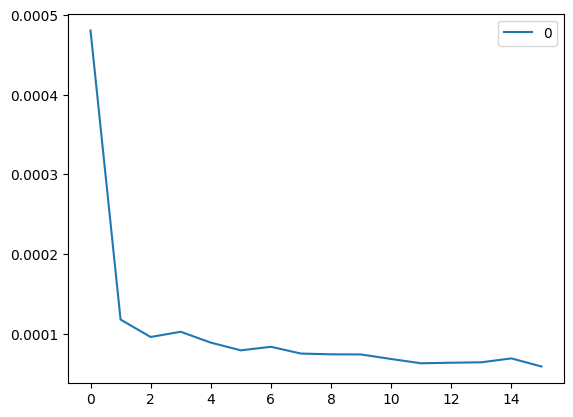

In [91]:
pd.DataFrame(history.history["loss"]).plot()

In [92]:
y_pred = model.predict(X_test)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step


In [93]:
y_pred

array([[0.1126892 ],
       [0.11327928],
       [0.11329997],
       [0.11316775],
       [0.11285797],
       [0.11270709],
       [0.11293668],
       [0.11341934],
       [0.11302817],
       [0.11222173],
       [0.11144602],
       [0.11120026],
       [0.11140607],
       [0.11231978],
       [0.11374724],
       [0.11696272],
       [0.12078099],
       [0.12211806],
       [0.12290247],
       [0.12384787],
       [0.12395641],
       [0.12442553],
       [0.12748192],
       [0.13122214],
       [0.13281652],
       [0.13444096],
       [0.13571605],
       [0.13649496],
       [0.13522409],
       [0.13430578],
       [0.13396576],
       [0.13331796],
       [0.13202529],
       [0.13072203],
       [0.13024999],
       [0.1318039 ],
       [0.13498221],
       [0.13847509],
       [0.14124613],
       [0.14314868],
       [0.1436747 ],
       [0.14429522],
       [0.14464286],
       [0.14422026],
       [0.14447798],
       [0.14641197],
       [0.14803894],
       [0.149

In [94]:
y_pred_true = scaler_y.inverse_transform(y_pred)
y_test_true = scaler_y.inverse_transform(y_test)

y_pred_true,y_test_true

(array([[ 7772.0845],
        [ 7811.8496],
        [ 7813.243 ],
        [ 7804.3335],
        [ 7783.4575],
        [ 7773.2905],
        [ 7788.7617],
        [ 7821.2876],
        [ 7794.9272],
        [ 7740.5825],
        [ 7688.3086],
        [ 7671.7466],
        [ 7685.616 ],
        [ 7747.19  ],
        [ 7843.385 ],
        [ 8060.0713],
        [ 8317.38  ],
        [ 8407.483 ],
        [ 8460.344 ],
        [ 8524.053 ],
        [ 8531.367 ],
        [ 8562.98  ],
        [ 8768.947 ],
        [ 9020.996 ],
        [ 9128.438 ],
        [ 9237.907 ],
        [ 9323.834 ],
        [ 9376.324 ],
        [ 9290.682 ],
        [ 9228.798 ],
        [ 9205.885 ],
        [ 9162.23  ],
        [ 9075.118 ],
        [ 8987.294 ],
        [ 8955.483 ],
        [ 9060.199 ],
        [ 9274.382 ],
        [ 9509.763 ],
        [ 9696.499 ],
        [ 9824.709 ],
        [ 9860.157 ],
        [ 9901.974 ],
        [ 9925.4   ],
        [ 9896.922 ],
        [ 9914.289 ],
        [1

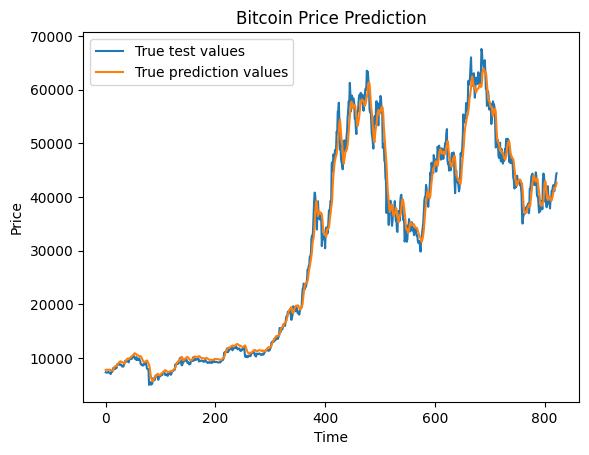

In [99]:
plt.plot(y_test_true.flatten(),label = "True test values")
plt.plot(y_pred_true.flatten(),label = "True prediction values")
plt.title("Bitcoin Price Prediction")
plt.xlabel("Time")
plt.ylabel("Price")
plt.legend()
plt.show()